# Smart Study Planner - Model Training Notebook

**Goal:** Predict how many hours per day a student should spend on a subject, using the subject's difficulty, the student's confidence, last test score, topics remaining, days left before the exam and daily free time.

**Dataset:** `data.csv` (simulated, 6000 rows) created by `generate_data.py`.

**Steps:** Load data -> Explore -> Preprocess -> Train models -> Evaluate -> Save `model.joblib` for the Streamlit app (`app.py`).

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the dataset

In [2]:
df = pd.read_csv("data.csv")
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (6000, 8)


,Subject_Type,Subject_Difficulty,Confidence,Last_Test_Score,Topics_Remaining,Days_Left,Daily_Free_Hours,Recommended_Hours_Per_Day
0,Programming,3,3,78,7,43,5,0.25
1,Practical,2,2,32,10,45,4,0.50
2,Programming,3,3,44,16,22,5,2.00
3,Mathematical,2,3,46,24,30,9,1.75
4,Theory,1,3,49,10,43,4,0.25


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Subject_Type               6000 non-null   str    
 1   Subject_Difficulty         6000 non-null   int64  
 2   Confidence                 6000 non-null   int64  
 3   Last_Test_Score            6000 non-null   int64  
 4   Topics_Remaining           6000 non-null   int64  
 5   Days_Left                  6000 non-null   int64  
 6   Daily_Free_Hours           6000 non-null   int64  
 7   Recommended_Hours_Per_Day  6000 non-null   float64
dtypes: float64(1), int64(6), str(1)
memory usage: 375.1 KB


## 3. Data quality check

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
df.describe().round(2)

Missing values per column:
Subject_Type                 0
Subject_Difficulty           0
Confidence                   0
Last_Test_Score              0
Topics_Remaining             0
Days_Left                    0
Daily_Free_Hours             0
Recommended_Hours_Per_Day    0
dtype: int64

Duplicate rows: 0


,Subject_Difficulty,Confidence,Last_Test_Score,Topics_Remaining,Days_Left,Daily_Free_Hours,Recommended_Hours_Per_Day
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,3.06,3.20,56.98,15.97,31.24,5.34,1.42
std,1.11,1.04,16.18,8.30,20.45,2.06,1.09
min,1.00,1.00,5.00,2.00,2.00,2.00,0.25
25%,2.00,3.00,46.00,9.00,16.00,4.00,0.50
50%,3.00,3.00,57.00,16.00,26.00,5.00,1.25
75%,4.00,4.00,68.00,23.00,42.00,7.00,2.00
max,5.00,5.00,98.00,30.00,90.00,10.00,6.00


## 4. Exploratory Data Analysis (EDA)

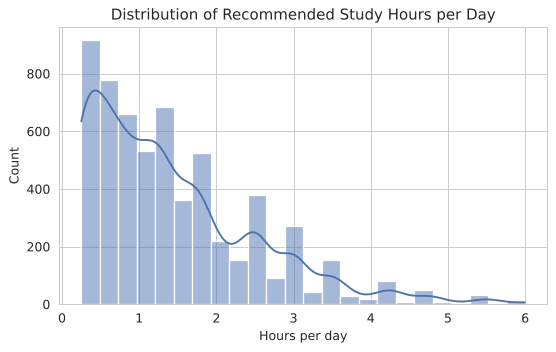

In [5]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Recommended_Hours_Per_Day"], bins=24, kde=True, color="#4C72B0")
plt.title("Distribution of Recommended Study Hours per Day")
plt.xlabel("Hours per day")
plt.show()

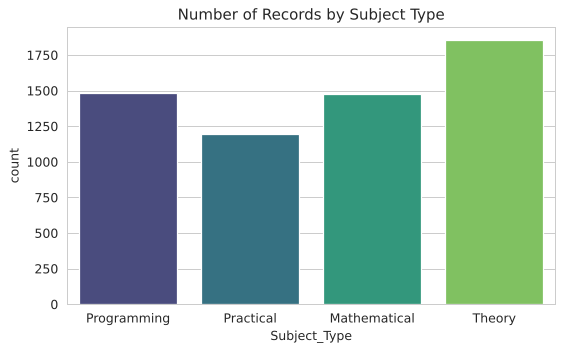

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(x="Subject_Type", data=df, palette="viridis")
plt.title("Number of Records by Subject Type")
plt.show()

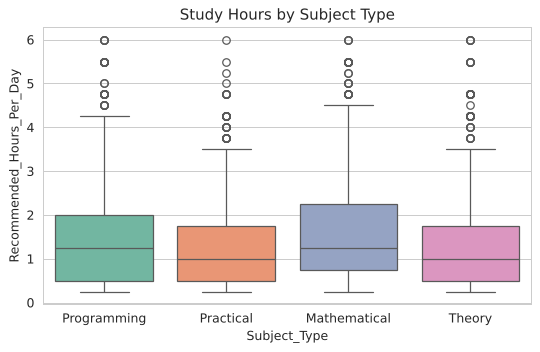

In [7]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="Subject_Type", y="Recommended_Hours_Per_Day", data=df, palette="Set2")
plt.title("Study Hours by Subject Type")
plt.show()

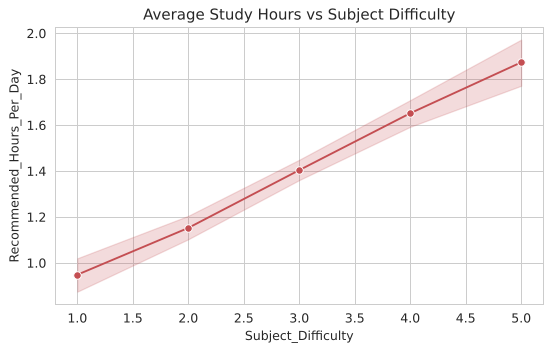

In [8]:
plt.figure(figsize=(7, 4))
sns.lineplot(x="Subject_Difficulty", y="Recommended_Hours_Per_Day", data=df, marker="o", color="#C44E52")
plt.title("Average Study Hours vs Subject Difficulty")
plt.show()

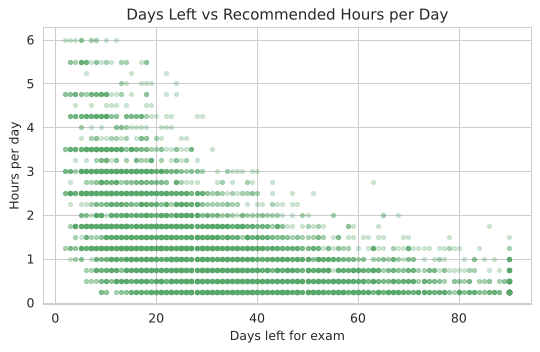

In [9]:
plt.figure(figsize=(7, 4))
plt.scatter(df["Days_Left"], df["Recommended_Hours_Per_Day"], alpha=0.25, s=10, color="#55A868")
plt.title("Days Left vs Recommended Hours per Day")
plt.xlabel("Days left for exam")
plt.ylabel("Hours per day")
plt.show()

## 5. Preprocessing

`Subject_Type` is text, so it is converted to numbers (label encoding).

In [10]:
type_map = {name: i for i, name in enumerate(sorted(df["Subject_Type"].unique()))}
print("Subject type encoding:", type_map)

data = df.copy()
data["Subject_Type"] = data["Subject_Type"].map(type_map)
data.head()

Subject type encoding: {'Mathematical': 0, 'Practical': 1, 'Programming': 2, 'Theory': 3}


,Subject_Type,Subject_Difficulty,Confidence,Last_Test_Score,Topics_Remaining,Days_Left,Daily_Free_Hours,Recommended_Hours_Per_Day
0,2,3,3,78,7,43,5,0.25
1,1,2,2,32,10,45,4,0.50
2,2,3,3,44,16,22,5,2.00
3,0,2,3,46,24,30,9,1.75
4,3,1,3,49,10,43,4,0.25


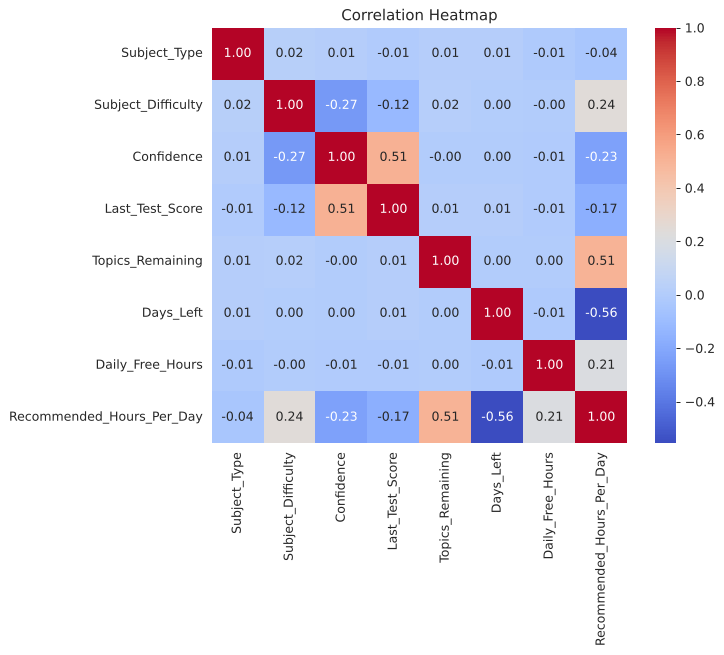

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap")
plt.show()

## 6. Train-test split

In [12]:
features = ["Subject_Type", "Subject_Difficulty", "Confidence", "Last_Test_Score",
            "Topics_Remaining", "Days_Left", "Daily_Free_Hours"]
target = "Recommended_Hours_Per_Day"

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 4800
Testing rows : 1200


## 7. Train and compare models

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=4, random_state=42),
}

results = []
trained = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred),
    })
    trained[name] = model

results_df = pd.DataFrame(results).round(3)
results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.448,0.606,0.700
1,Random Forest,0.176,0.273,0.939
2,Gradient Boosting,0.167,0.241,0.952


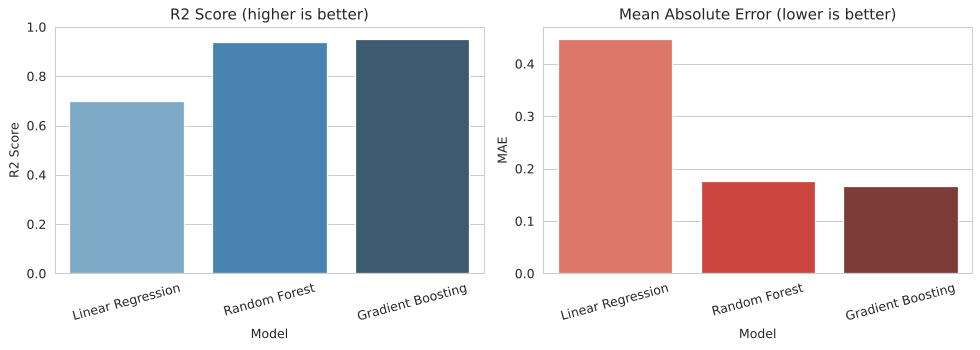

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x="Model", y="R2 Score", data=results_df, palette="Blues_d", ax=axes[0])
axes[0].set_title("R2 Score (higher is better)")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(x="Model", y="MAE", data=results_df, palette="Reds_d", ax=axes[1])
axes[1].set_title("Mean Absolute Error (lower is better)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 8. Select the best model

In [15]:
best_name = results_df.sort_values("R2 Score", ascending=False).iloc[0]["Model"]
best_model = trained[best_name]
print("Best model:", best_name)

cv = cross_val_score(best_model, X, y, cv=5, scoring="r2")
print("5-fold cross-validation R2 scores:", cv.round(3))
print("Average cross-validation R2     :", cv.mean().round(3))

Best model: Gradient Boosting
5-fold cross-validation R2 scores: [0.955 0.956 0.961 0.956 0.951]
Average cross-validation R2     : 0.956


## 9. Actual vs predicted

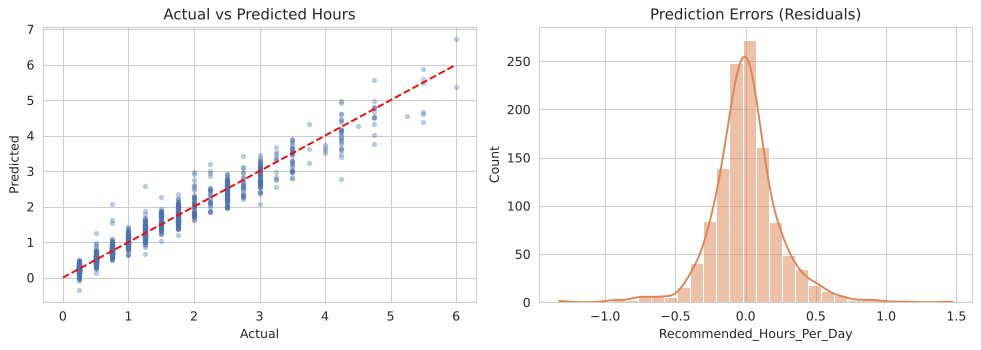

In [16]:
best_pred = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, best_pred, alpha=0.3, s=10, color="#4C72B0")
axes[0].plot([0, 6], [0, 6], "r--")
axes[0].set_title("Actual vs Predicted Hours")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

sns.histplot(y_test - best_pred, bins=30, kde=True, ax=axes[1], color="#DD8452")
axes[1].set_title("Prediction Errors (Residuals)")
plt.tight_layout()
plt.show()

## 10. Feature importance

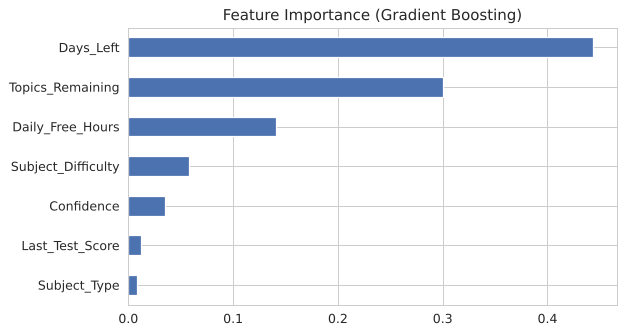

Days_Left             0.444
Topics_Remaining      0.301
Daily_Free_Hours      0.141
Subject_Difficulty    0.058
Confidence            0.035
Last_Test_Score       0.012
Subject_Type          0.009
dtype: float64

In [17]:
importance = pd.Series(best_model.feature_importances_, index=features).sort_values()
plt.figure(figsize=(7, 4))
importance.plot(kind="barh", color="#4C72B0")
plt.title(f"Feature Importance ({best_name})")
plt.show()
importance.sort_values(ascending=False).round(3)

## 11. Save the model

In [18]:
bundle = {
    "model": best_model,
    "model_name": best_name,
    "features": features,
    "subject_type_map": type_map,
    "metrics": results_df[results_df["Model"] == best_name].iloc[0].to_dict(),
}
joblib.dump(bundle, "model.joblib")
print("model.joblib saved")

model.joblib saved


## 12. Test the saved model

In [19]:
loaded = joblib.load("model.joblib")

sample = pd.DataFrame([{
    "Subject_Type": loaded["subject_type_map"]["Mathematical"],
    "Subject_Difficulty": 4,
    "Confidence": 2,
    "Last_Test_Score": 48,
    "Topics_Remaining": 18,
    "Days_Left": 20,
    "Daily_Free_Hours": 6,
}])[loaded["features"]]

hours = loaded["model"].predict(sample)[0]
print(f"Recommended study time: {hours:.2f} hours per day")

Recommended study time: 2.77 hours per day


## 13. Conclusion

The Gradient Boosting model gives the most accurate predictions of the required daily study hours. It is saved as `model.joblib` and used by the Streamlit app (`app.py`), which turns the predictions into a personalised weekly study timetable.